# Лабораторная №4. Сверточная нейронная сеть

Задание:  
1)	Реализовать полносверточную нейронную сеть (полностью сверточную сеть, без полносвязных слоев) на библиотеке Keras (можно PyTorch, JAX, TensorFlow) для сегментации клеточных стенок.
Выборка медицинских изображений клеточных мембран ISBI 2012: (https://drive.google.com/drive/folders/1fLDfatKLTiay1KZOXb5F-MIY-0gPnbvI?usp=share_link).
Описание выборки: (https://imagej.net/events/isbi-2012-segmentation-challenge).
Так как тестовая выборка не дана, использовать 5 изображений из обучающей выборки в качестве тестовой выборки.  
2)	Самостоятельно разметить Одно изображение из тестовой выборки данных, выделив клеточные стенки на изображении и сравнить с полученным результатом нейронной сети (получится желаемый результат для нейронной сети и точность на нем, можно попробовать использовать в помощь обученную нейронную сеть и поправить ее ответ). Постарайтесь взять разные изображения из тестовой выборки, чтобы не пересекаться.
(Можно попробовать использовать: Paint (сложно и долго), Photoshop, Krita (бесплатный аналог Photoshop)).


In [14]:
#подключение к гугл диску
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Загрузка изображений и масок

In [15]:
from pathlib import Path
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import random
import matplotlib.pyplot as plt
from collections import Counter

DATA_DIR = Path('/content/drive/MyDrive/membrane')

TRAIN_IMG = DATA_DIR / 'train' / 'image'
TRAIN_MSK = DATA_DIR / 'train' / 'mask'
TEST_IMG  = DATA_DIR / 'test'  / 'image'


def pair_files(img_dir, msk_dir):
    img_paths = sorted(
        img_dir.glob('*.png'),
        key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem
    )
    pairs = []
    for ip in img_paths:
        mp = msk_dir / ip.name
        if mp.exists():
            pairs.append((ip, mp))
        else:
            print(f'[warn] нет маски для {ip.name}')
    return pairs


train_pairs = pair_files(TRAIN_IMG, TRAIN_MSK)
test_img_paths = sorted(
    TEST_IMG.glob('*.png'),
    key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem
)

print(f'всего пар train: {len(train_pairs)}')
print(f'картинок без масок (test): {len(test_img_paths)}')

всего пар train: 30
картинок без масок (test): 30


## Разделение на train и test

In [16]:
SEED = 42
random.seed(SEED)

indices = list(range(len(train_pairs)))
random.shuffle(indices)

N_TEST = 5
test_idx  = sorted(indices[:N_TEST])
train_idx = sorted(indices[N_TEST:])

train_pairs_split = [train_pairs[i] for i in train_idx]
test_pairs_split  = [train_pairs[i] for i in test_idx]

print('test_idx :', test_idx)
print('train    :', len(train_pairs_split))
print('test     :', len(test_pairs_split))
for ip, mp in test_pairs_split:
    print('  test file:', ip.name, '<->', mp.name)

test_idx : [10, 14, 19, 22, 26]
train    : 25
test     : 5
  test file: 10.png <-> 10.png
  test file: 14.png <-> 14.png
  test file: 19.png <-> 19.png
  test file: 22.png <-> 22.png
  test file: 26.png <-> 26.png


## Dataset

In [17]:
class MembraneDataset(Dataset):
    def __init__(self, pairs, size=(512, 512), train=False):
        self.pairs = pairs
        self.size = size # (W, H) — как у PIL
        self.train = train

    def __len__(self):
        return len(self.pairs)

    def _load(self, img_path, msk_path):
        img = Image.open(img_path).convert('L')
        msk = Image.open(msk_path).convert('L')

        # ресайз: картинка — билинейно, маска — nearest, чтобы не размыть 0/1
        img = img.resize(self.size, Image.BILINEAR)
        msk = msk.resize(self.size, Image.NEAREST)

        img = np.asarray(img, dtype=np.float32) / 255.0       # [H, W] в [0, 1]
        msk = np.asarray(msk, dtype=np.float32)
        if msk.max() > 1.0:
            msk = msk / 255.0
        msk = (msk > 0.5).astype(np.float32)                  # [H, W] в {0, 1}
        return img, msk

    def __getitem__(self, idx):
        img, msk = self._load(*self.pairs[idx])

        if self.train:
            if random.random() < 0.5:
                img, msk = np.fliplr(img), np.fliplr(msk)
            if random.random() < 0.5:
                img, msk = np.flipud(img), np.flipud(msk)
            k = random.randint(0, 3)
            if k:
                img, msk = np.rot90(img, k), np.rot90(msk, k)
            img  = np.ascontiguousarray(img)
            msk  = np.ascontiguousarray(msk)

        img = torch.from_numpy(img).unsqueeze(0).float()       # [1, H, W]
        msk = torch.from_numpy(msk).unsqueeze(0).float()       # [1, H, W]
        return img, msk

In [18]:
class InferenceDataset(Dataset):
    def __init__(self, img_paths, size=(256, 256)):
        self.img_paths = img_paths
        self.size = size

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        p = self.img_paths[idx]
        img = Image.open(p).convert('L').resize(self.size, Image.BILINEAR)
        img = np.asarray(img, dtype=np.float32) / 255.0
        img = torch.from_numpy(np.ascontiguousarray(img)).unsqueeze(0).float()
        return img, p.name

## DataLoader

In [19]:
IMG_SIZE = (256, 256)

train_ds = MembraneDataset(train_pairs_split, size=IMG_SIZE, train=True)
test_ds  = MembraneDataset(test_pairs_split,  size=IMG_SIZE, train=False)
infer_ds = InferenceDataset(test_img_paths, size=IMG_SIZE)

train_loader = DataLoader(
    train_ds, batch_size=4, shuffle=True,
    num_workers=0, pin_memory=True, drop_last=True,
)

test_loader = DataLoader(
    test_ds, batch_size=1, shuffle=False,
    num_workers=0, pin_memory=True,
)

infer_loader = DataLoader(
    infer_ds, batch_size=1, shuffle=False,
    num_workers=0, pin_memory=True,
)

In [20]:
imgs, msks = next(iter(train_loader))
print('train images:', imgs.shape, imgs.dtype, float(imgs.min()), float(imgs.max()))
print('train masks :', msks.shape, 'уникальные:', torch.unique(msks))

imgs, msks = next(iter(test_loader))
print('test  images:', imgs.shape, 'masks:', msks.shape)

imgs, names = next(iter(infer_loader))
print('infer images:', imgs.shape, 'name:', names)

train images: torch.Size([4, 1, 256, 256]) torch.float32 0.007843137718737125 0.9882352948188782
train masks : torch.Size([4, 1, 256, 256]) уникальные: tensor([0., 1.])
test  images: torch.Size([1, 1, 256, 256]) masks: torch.Size([1, 1, 256, 256])
infer images: torch.Size([1, 1, 256, 256]) name: ('0.png',)


## Модель

In [21]:
import torch
import torch.nn as nn


class DoubleConv(nn.Module):
    """Conv -> BN -> ReLU, дважды подряд."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    """Downscaling: MaxPool -> DoubleConv."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_ch, out_ch),
        )

    def forward(self, x):
        return self.block(x)


class Up(nn.Module):
    """Upscaling: ConvTranspose -> concat skip -> DoubleConv."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        # если размеры не совпали (бывает при нечётных H/W) — подгоняем
        if x.shape[-2:] != skip.shape[-2:]:
            x = nn.functional.interpolate(
                x, size=skip.shape[-2:], mode='bilinear', align_corners=False
            )
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)


class UNet(nn.Module):
    """
    Полносверточная U-Net без Linear/Dense слоёв.
    Вход : [B, in_channels, H, W]
    Выход: [B, out_channels, H, W] — вероятности после sigmoid.
    """
    def __init__(self, in_channels=1, out_channels=1, base=32):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.base = base

        self.inc   = DoubleConv(in_channels, base)         # 256 -> 256
        self.down1 = Down(base,     base * 2)              # 256 -> 128
        self.down2 = Down(base * 2, base * 4)              # 128 -> 64
        self.down3 = Down(base * 4, base * 8)              # 64  -> 32
        self.down4 = Down(base * 8, base * 16)             # 32  -> 16

        self.up1 = Up(base * 16, base * 8)                 # 16  -> 32
        self.up2 = Up(base * 8,  base * 4)                 # 32  -> 64
        self.up3 = Up(base * 4,  base * 2)                 # 64  -> 128
        self.up4 = Up(base * 2,  base)                     # 128 -> 256

        self.out_conv = nn.Conv2d(base, out_channels, kernel_size=1)  # 1x1

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x,  x3)
        x = self.up3(x,  x2)
        x = self.up4(x,  x1)

        return self.out_conv(x)

## Функция потерь: BCE + Dice

In [22]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, target):
        # logits: [B,1,H,W] без sigmoid, target: [B,1,H,W] в {0,1}
        probs = torch.sigmoid(logits)
        probs = probs.contiguous().view(probs.size(0), -1)
        target = target.contiguous().view(target.size(0), -1)

        intersection = (probs * target).sum(dim=1)
        union = probs.sum(dim=1) + target.sum(dim=1)

        dice = (2 * intersection + self.eps) / (union + self.eps)
        return 1 - dice.mean()


class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, target):
        return self.bce_weight * self.bce(logits, target) + \
               (1 - self.bce_weight) * self.dice(logits, target)

## Метрики: Dice и IoU

In [23]:
@torch.no_grad()
def dice_iou_from_logits(logits, target, threshold=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    pred = (probs > threshold).float()
    target = target.float()

    pred = pred.contiguous().view(pred.size(0), -1)
    target = target.contiguous().view(target.size(0), -1)

    inter = (pred * target).sum(dim=1)
    union = pred.sum(dim=1) + target.sum(dim=1)

    dice = (2 * inter + eps) / (union + eps)
    iou  = (inter + eps) / (union - inter + eps)
    return dice.mean().item(), iou.mean().item()

## Обучение

In [24]:
from tqdm.auto import tqdm
from collections import defaultdict

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for imgs, msks in tqdm(loader, leave=False):
        imgs, msks = imgs.to(device), msks.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, msks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_dice, total_iou, n = 0.0, 0.0, 0.0, 0
    for imgs, msks in loader:
        imgs, msks = imgs.to(device), msks.to(device)
        logits = model(imgs)
        loss = criterion(logits, msks)
        d, i = dice_iou_from_logits(logits, msks)
        bs = imgs.size(0)
        total_loss += loss.item() * bs
        total_dice += d * bs
        total_iou  += i * bs
        n += bs
    return total_loss / n, total_dice / n, total_iou / n


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = UNet(in_channels=1, out_channels=1, base=32).to(device)
criterion = BCEDiceLoss(bce_weight=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 100


history = defaultdict(list)

for epoch in range(1, EPOCHS + 1):
    tr_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    va_loss, va_dice, va_iou = evaluate(model, test_loader, criterion, device)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['val_dice'].append(va_dice)
    history['val_iou'].append(va_iou)

    print(f'[{epoch:02d}] train_loss={tr_loss:.4f} | '
          f'val_loss={va_loss:.4f} dice={va_dice:.4f} iou={va_iou:.4f}')

  0%|          | 0/6 [00:00<?, ?it/s]

[01] train_loss=0.3628 | val_loss=0.4994 dice=0.8818 iou=0.7888


  0%|          | 0/6 [00:00<?, ?it/s]

[02] train_loss=0.2920 | val_loss=0.4283 dice=0.8818 iou=0.7888


  0%|          | 0/6 [00:00<?, ?it/s]

[03] train_loss=0.2680 | val_loss=0.3758 dice=0.8818 iou=0.7888


... (190 outputs left out)

  0%|          | 0/6 [00:00<?, ?it/s]

[99] train_loss=0.1316 | val_loss=0.1399 dice=0.9428 iou=0.8918


  0%|          | 0/6 [00:00<?, ?it/s]

[100] train_loss=0.1275 | val_loss=0.1346 dice=0.9457 iou=0.8970


## Графики потерь и метрик

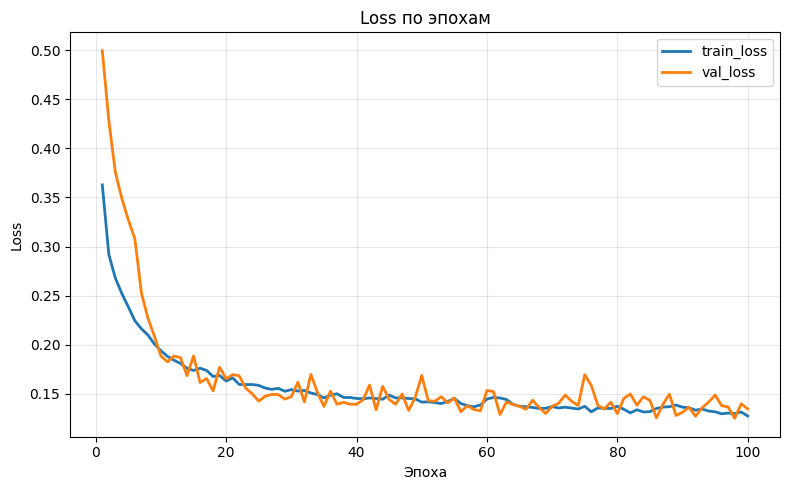

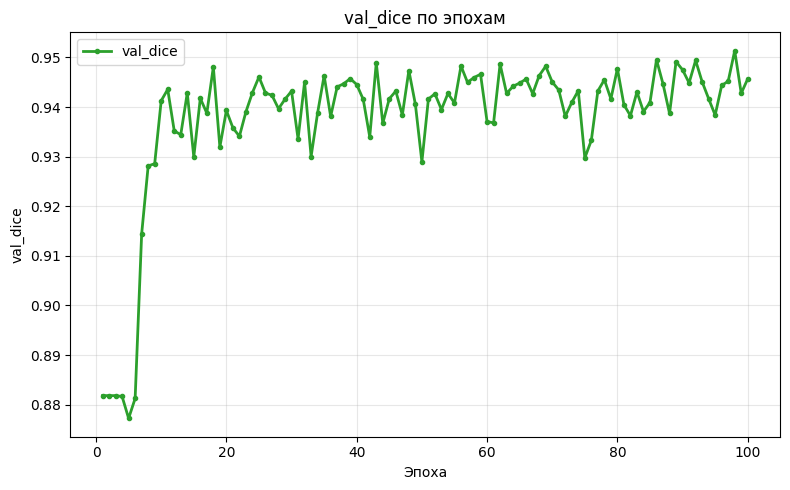

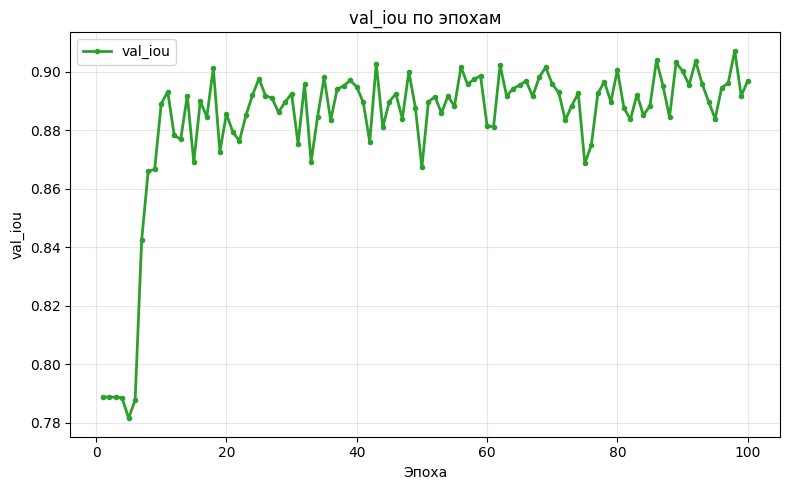

In [25]:
import matplotlib.pyplot as plt


def plot_training_history(history, save_dir=None):
    """
    Строит:
      1) train_loss и val_loss на одном графике;
      2) отдельные графики для каждой val-метрики (val_dice, val_iou, ...).

    history  — dict / defaultdict(list), где ключи вроде 'train_loss',
               'val_loss', 'val_dice', 'val_iou', ... значения — списки float.
    save_dir — Path или None. Если задан, сохранит png-файлы туда.
    """
    # длины всех серий
    n_epochs = max(len(v) for v in history.values())
    epochs = range(1, n_epochs + 1)

    # ---- 1. Loss: train + val на одном графике ----
    loss_keys = [k for k in ('train_loss', 'val_loss') if k in history]
    if loss_keys:
        plt.figure(figsize=(8, 5))
        for key in loss_keys:
            plt.plot(epochs[:len(history[key])],
                     history[key],
                     label=key,
                     linewidth=2)
        plt.title('Loss по эпохам')
        plt.xlabel('Эпоха')
        plt.ylabel('Loss')
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()

        if save_dir is not None:
            from pathlib import Path
            save_dir = Path(save_dir)
            save_dir.mkdir(parents=True, exist_ok=True)
            plt.savefig(save_dir / 'loss.png', dpi=120, bbox_inches='tight')

        plt.show()
        plt.close()

    # ---- 2. Метрики: отдельный график на каждую ----
    metric_keys = [k for k in history if k.startswith('val_') and k != 'val_loss']

    for key in metric_keys:
        plt.figure(figsize=(8, 5))
        plt.plot(epochs[:len(history[key])],
                 history[key],
                 label=key,
                 color='tab:green',
                 linewidth=2,
                 marker='o',
                 markersize=3)
        plt.title(f'{key} по эпохам')
        plt.xlabel('Эпоха')
        plt.ylabel(key)
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()

        if save_dir is not None:
            plt.savefig(save_dir / f'{key}.png', dpi=120, bbox_inches='tight')

        plt.show()
        plt.close()

plot_training_history(history)

## Получаем самостоятельно размеченое изображение

loss = 0.1875 | dice = 0.9457 | iou = 0.8970


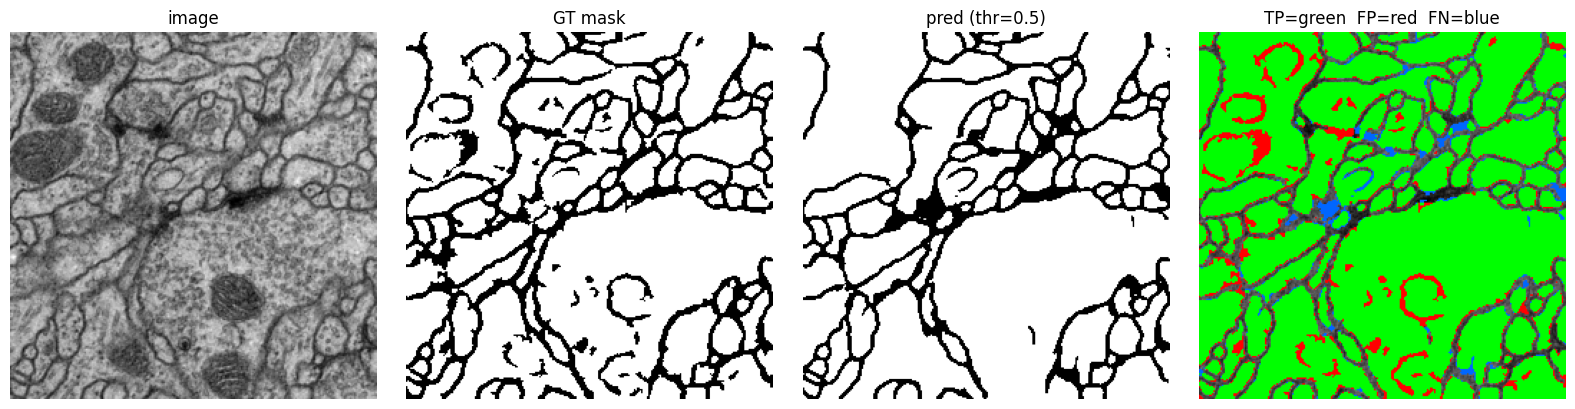

Dice = 0.9457 | IoU = 0.8970


In [30]:
import matplotlib.pyplot as plt
import torch


@torch.no_grad()
def show_prediction(model, dataset, idx=0, device='cuda', threshold=0.5):
    """
    Берёт dataset[idx] (img, mask), прогоняет модель,
    рисует: изображение | GT-маска | предсказание | overlay ошибок.
    """
    model.eval()

    img, msk = dataset[idx]                     # [1,H,W], [1,H,W]
    x = img.unsqueeze(0).to(device)             # [1,1,H,W]

    logits = model(x)
    prob = torch.sigmoid(logits)[0, 0].cpu().numpy()   # [H,W]
    pred = (prob > threshold).astype('float32')        # {0,1}
    gt   = msk[0].numpy()                              # {0,1}
    img_np = img[0].numpy()                            # [H,W]

    # overlay: TP=зелёный, FP=красный, FN=синий
    overlay = np.zeros((*gt.shape, 3), dtype='float32')
    overlay[..., 0] = img_np                # фон = изображение в красном канале
    overlay[..., 1] = img_np
    overlay[..., 2] = img_np
    tp = (pred == 1) & (gt == 1)
    fp = (pred == 1) & (gt == 0)
    fn = (pred == 0) & (gt == 1)
    overlay[tp] = [0, 1, 0]                 # зелёный  — верно предсказано
    overlay[fp] = [1, 0, 0]                 # красный  — лишнее
    overlay[fn] = [0, 0.4, 1]               # синий    — пропущено

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    axes[0].imshow(img_np, cmap='gray')
    axes[0].set_title('image')
    axes[0].axis('off')

    axes[1].imshow(gt, cmap='gray')
    axes[1].set_title('GT mask')
    axes[1].axis('off')

    axes[2].imshow(pred, cmap='gray')
    axes[2].set_title(f'pred (thr={threshold})')
    axes[2].axis('off')

    axes[3].imshow(overlay)
    axes[3].set_title('TP=green  FP=red  FN=blue')
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()

    d = (2 * (pred * gt).sum() + 1e-6) / (pred.sum() + gt.sum() + 1e-6)
    i = ((pred * gt).sum() + 1e-6) / ((pred + gt - pred * gt).sum() + 1e-6)
    print(f'Dice = {d:.4f} | IoU = {i:.4f}')

mask_path = Path('/content/drive/MyDrive/29.png')
image_path = TEST_IMG / '29.png'
pair = (image_path, mask_path)

ds = MembraneDataset([pair], size=IMG_SIZE, train=False)

loader = DataLoader(
    ds, batch_size=1, shuffle=False,
    num_workers=0, pin_memory=True,
)

loss, dice, iou = evaluate(model, loader, criterion, device)
print(f'loss = {loss:.4f} | dice = {dice:.4f} | iou = {iou:.4f}')
show_prediction(model, ds, idx=0, device=device, threshold=0.5)